##Importing dataset

In [1]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="S8ISFlXP33uib9GihAx4")
project = rf.workspace("fastercnn-lot96").project("finallysave")
version = project.version(1)
dataset = version.download("coco")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.9/79.9 kB 7.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 kB 5.2 MB/s eta 0:00:00
  Attempting uninstall: idna
    Found existing installation: idna 3.8
    Uninstalling idna-3.8:
      Successfully uninstalled idna-3.8
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to FinallySAVE-1 in coco:: 100%|██████████| 2698/2698 [00:00<00:00, 5413.33it/s]


In [2]:
# Install PyTorch and TorchVision
!pip install torch torchvision

# Install additional packages
!pip install seaborn scikit-learn pillow
!pip install scikit-learn seaborn matplotlib



## Training

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth
100%|██████████| 160M/160M [00:00<00:00, 217MB/s]
`torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
`torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.


Epoch 1/600, total_loss: 0.2997839526604798
Epoch 1/600, loss_classifier: 0.16266194131162207
Epoch 1/600, loss_box_reg: 0.10394833060139316
Epoch 1/600, loss_objectness: 0.026228573485040815
Epoch 1/600, loss_rpn_box_reg: 0.0069451057549439746
Epoch 2/600, total_loss: 0.21502330242577244
Epoch 2/600, loss_classifier: 0.1037695932565099
Epoch 2/600, loss_box_reg: 0.09299580209841163
Epoch 2/600, loss_objectness: 0.012209171995567947
Epoch 2/600, loss_rpn_box_reg: 0.006048734443877839
Epoch 3/600, total_loss: 0.1926286028603376
Epoch 3/600, loss_classifier: 0.09380906094181335
Epoch 3/600, loss_box_reg: 0.08303875637130212
Epoch 3/600, loss_objectness: 0.01018299386733985
Epoch 3/600, loss_rpn_box_reg: 0.005597790851163031
Epoch 4/600, total_loss: 0.17949373988529382
Epoch 4/600, loss_classifier: 0.08557780516349663
Epoch 4/600, loss_box_reg: 0.0801851429613465
Epoch 4/600, loss_objectness: 0.008305655541766625
Epoch 4/600, loss_rpn_box_reg: 0.005425136009531127
Epoch 5/600, total_loss:

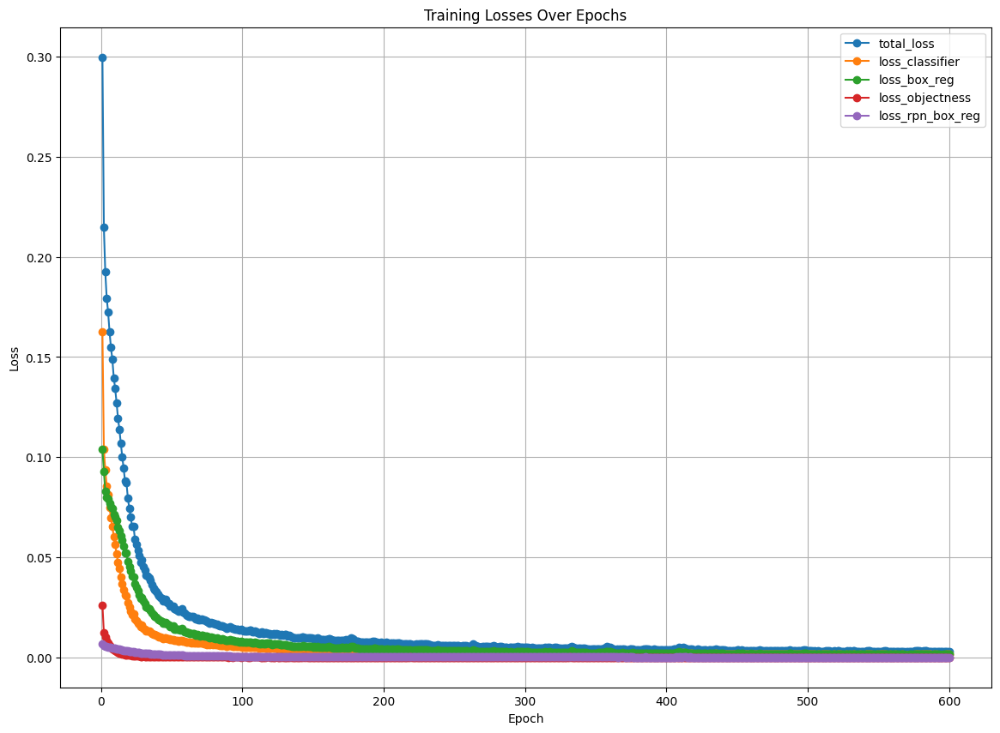

Model saved to faster_rcnn_model.pth
True Labels: [1 3 4 4 4 4 2 4 1 1 4 1 1 4 2 4 1 2 4 1 1 1 1 1 2 1 2 3 3 1 1 1 4 4 3 2 1
 1 2 1 1 1 4 2 1 4 2 1 1 4 1 2 1 4 3 2 4 1 4 4 4 1 4 3 2 1 4 2 1 4 1 2 1 2
 4 1 2 1 1 2 4 1 1 4 2 1 1 2 1 2 2 1 1 1 1 4 4 4 4 1 2 1 1 1 2 1 2 1 1 1 2
 4 1 2 4 4 4 2 1 3 2 4 1 2 2 2 4 1 2 1 3 1 4 2 4 1 4 1 2 4 4 2 1 3 3 4 2 1
 3 4 4 1 4 4 4 1 1 4 4 2 1 2 4 4 2 1 2 1 3 2 4 1 2 3 2 4 1 1 2 2 2 4 4 1 1]
Predicted Labels: [1 3 4 4 4 4 2 4 1 1 4 1 1 4 2 4 1 2 4 1 1 1 1 1 2 1 2 3 3 1 1 1 4 4 3 2 1
 1 2 1 1 1 4 2 1 4 2 1 1 4 1 2 1 4 3 2 4 1 4 4 4 1 4 3 2 1 4 2 1 4 1 2 1 2
 4 1 2 1 1 2 4 1 1 4 2 1 1 2 1 2 2 1 1 1 1 4 4 4 4 1 2 1 1 1 2 1 2 1 1 1 2
 4 1 2 4 4 4 2 1 3 2 4 1 2 2 2 4 1 2 1 3 1 4 2 4 1 4 1 2 4 4 2 1 3 3 2 2 1
 3 4 4 1 4 4 4 1 1 4 4 2 1 2 4 4 2 1 2 1 2 2 4 1 2 3 2 4 1 1 2 2 2 4 4 1 1]


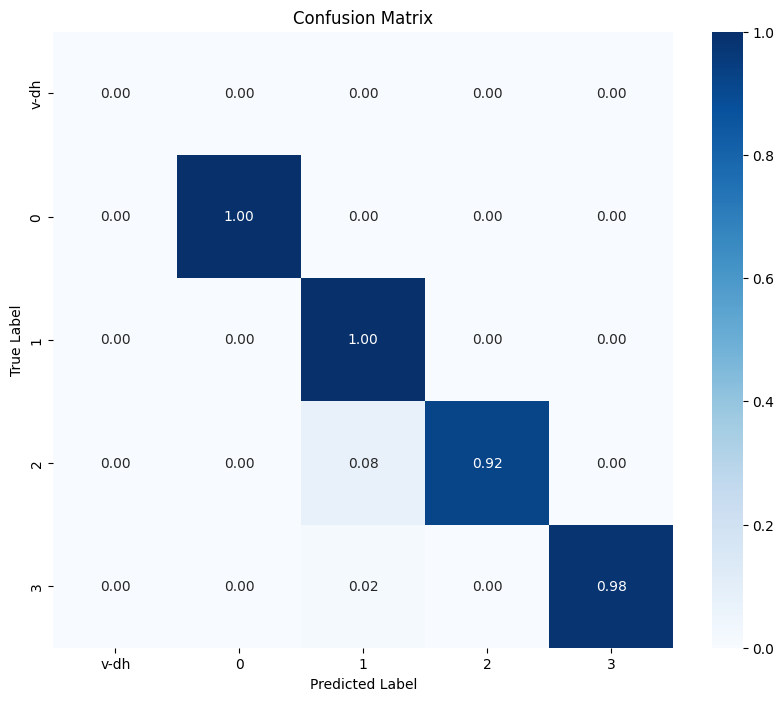

In [3]:
import os
import json
import torch
import torchvision
from torch.utils.data import Dataset, DataLoader
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.transforms import functional as F
import torchvision.transforms as T
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from torch.cuda.amp import GradScaler, autocast

# Custom Dataset class
class CustomDataset(Dataset):
    def __init__(self, image_dir, annotation_file, transforms=None):
        self.image_dir = image_dir
        self.transforms = transforms

        # Load COCO annotations
        with open(annotation_file, 'r') as f:
            self.coco = json.load(f)

        # Extract image IDs and categories, excluding 'skin_cancer'
        self.image_ids = [img['id'] for img in self.coco['images']]
        self.categories = {cat['id']: cat['name'] for cat in self.coco['categories']}
        self.category_to_idx = {cat: idx for idx, cat in enumerate(self.categories.values())}
        self.img_id_to_path = {img['id']: img['file_name'] for img in self.coco['images']}

        # Load annotations, excluding those with 'skin_cancer' class
        self.img_id_to_annotations = self._load_annotations()

    def _load_annotations(self):
        img_id_to_annotations = {}
        for ann in self.coco['annotations']:
            img_id = ann['image_id']
            category_id = ann['category_id']

            # Skip annotations with 'skin_cancer' category
            if category_id not in self.categories:
                continue

            bbox = ann['bbox']
            if img_id not in img_id_to_annotations:
                img_id_to_annotations[img_id] = {'boxes': [], 'labels': []}
            img_id_to_annotations[img_id]['boxes'].append([bbox[0], bbox[1], bbox[0] + bbox[2], bbox[1] + bbox[3]])
            img_id_to_annotations[img_id]['labels'].append(self.category_to_idx[self.categories[category_id]])

        return img_id_to_annotations

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, idx):
        img_id = self.image_ids[idx]
        image_path = os.path.join(self.image_dir, self.img_id_to_path[img_id])
        image = Image.open(image_path).convert("RGB")

        targets = self.img_id_to_annotations.get(img_id, {'boxes': [], 'labels': []})
        boxes = torch.tensor(targets['boxes'], dtype=torch.float32)
        labels = torch.tensor(targets['labels'], dtype=torch.int64)

        # Ensure boxes and labels are not empty
        if boxes.numel() == 0:
            boxes = torch.empty((0, 4), dtype=torch.float32)
        if labels.numel() == 0:
            labels = torch.empty((0,), dtype=torch.int64)

        targets = {'boxes': boxes, 'labels': labels}

        if self.transforms:
            image = self.transforms(image)

        return image, targets

# Collate function for DataLoader
def collate_fn(batch):
    return tuple(zip(*batch))

# Function to create data loaders
def create_data_loaders(train_dir, test_dir, valid_dir, transforms, batch_size=16):
    train_dataset = CustomDataset(train_dir, os.path.join(train_dir, '_annotations.coco.json'), transforms)
    test_dataset = CustomDataset(test_dir, os.path.join(test_dir, '_annotations.coco.json'), transforms)
    valid_dataset = CustomDataset(valid_dir, os.path.join(valid_dir, '_annotations.coco.json'), transforms)

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2, collate_fn=collate_fn)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2, collate_fn=collate_fn)
    valid_loader = DataLoader(valid_dataset, batch_size=batch_size, shuffle=False, num_workers=2, collate_fn=collate_fn)

    return train_loader, test_loader, valid_loader, train_dataset

# Function to create the Faster R-CNN model
def create_model(num_classes):
    weights = torchvision.models.detection.FasterRCNN_ResNet50_FPN_Weights.COCO_V1
    model = fasterrcnn_resnet50_fpn(weights=weights)
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)
    return model

# Function to train the model and record losses
def train_model(model, dataloader, optimizer, device, num_epochs=600):
    model.train()
    scaler = GradScaler()

    # Dictionaries to store different losses
    loss_values = {
        'total_loss': [],
        'loss_classifier': [],
        'loss_box_reg': [],
        'loss_objectness': [],
        'loss_rpn_box_reg': []
    }

    for epoch in range(num_epochs):
        running_loss = {key: 0.0 for key in loss_values.keys()}

        for images, targets in dataloader:
            images = [img.to(device) for img in images]
            targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

            optimizer.zero_grad()
            with autocast():
                loss_dict = model(images, targets)
                losses = sum(loss for loss in loss_dict.values())

            scaler.scale(losses).backward()
            scaler.step(optimizer)
            scaler.update()

            # Accumulate losses for the epoch
            for key in loss_values.keys():
                if key == 'total_loss':
                    running_loss[key] += losses.item()
                elif key in loss_dict:
                    running_loss[key] += loss_dict[key].item()

        # Compute average losses for the epoch
        for key in loss_values.keys():
            epoch_loss = running_loss[key] / len(dataloader)
            loss_values[key].append(epoch_loss)
            print(f"Epoch {epoch+1}/{num_epochs}, {key}: {epoch_loss}")

    return loss_values

# Function to plot the training loss
def plot_losses(loss_values):
    plt.figure(figsize=(14, 10))
    for key, values in loss_values.items():
        plt.plot(range(1, len(values) + 1), values, marker='o', label=key)
    plt.title('Training Losses Over Epochs')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    plt.show()

# Function to plot the confusion matrix
def plot_confusion_matrix(true_labels, pred_labels, class_names):
    conf_matrix = confusion_matrix(true_labels, pred_labels, labels=np.arange(len(class_names)))

    with np.errstate(divide='ignore', invalid='ignore'):
        row_sums = conf_matrix.sum(axis=1, keepdims=True)
        conf_matrix_normalized = conf_matrix / row_sums
        conf_matrix_normalized[np.isnan(conf_matrix_normalized)] = 0

    plt.figure(figsize=(10, 8))
    sns.heatmap(conf_matrix_normalized, annot=True, fmt=".2f", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.title('Confusion Matrix')
    plt.show()

# Function to save the model
def save_model(model, save_path):
    torch.save(model.state_dict(), save_path)
    print(f"Model saved to {save_path}")

# Function to evaluate the model
def evaluate_model(model, dataloader, device):
    model.eval()
    all_labels = []
    all_preds = []

    with torch.no_grad():
        for images, targets in dataloader:
            images = [img.to(device) for img in images]
            outputs = model(images)

            for i, output in enumerate(outputs):
                pred_labels = output['labels'].cpu().numpy()
                true_labels = targets[i]['labels'].cpu().numpy()

                # Exclude background class
                pred_labels = pred_labels[pred_labels != 0]
                true_labels = true_labels[true_labels != 0]

                if len(pred_labels) > 0 and len(true_labels) > 0:
                    if len(pred_labels) == len(true_labels):
                        all_preds.extend(pred_labels)
                        all_labels.extend(true_labels)

    return np.array(all_labels), np.array(all_preds)

# Define transformations
transforms = T.Compose([
    T.ToTensor(),
    T.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),
])

# Paths to your datasets
train_image_dir = '/content/FinallySAVE-1/train'
test_image_dir = '/content/FinallySAVE-1/test'
valid_image_dir = '/content/FinallySAVE-1/valid'

# Set the batch size
batch_size = 16

# Create data loaders
train_loader, test_loader, valid_loader, train_dataset = create_data_loaders(train_image_dir, test_image_dir, valid_image_dir, transforms, batch_size=batch_size)

# Create model with the correct number of classes (excluding 'skin_cancer')
num_classes = len(train_dataset.categories)  # No need to subtract 1, since 'skin_cancer' is excluded
model = create_model(num_classes)

# Move model to GPU if available
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model.to(device)

# Define optimizer
optimizer = torch.optim.SGD(model.parameters(), lr=0.005, momentum=0.9)

# Train the model and record all losses
loss_values = train_model(model, train_loader, optimizer, device)

# Plot all the training losses
plot_losses(loss_values)

# Save the model
save_path = 'faster_rcnn_model.pth'
save_model(model, save_path)

# Evaluate the model
true_labels, pred_labels = evaluate_model(model, test_loader, device)

# Print the true and predicted labels
print("True Labels:", true_labels)
print("Predicted Labels:", pred_labels)

# Plot the confusion matrix
class_names = [name for name in train_dataset.categories.values() if name != 'skin_cancer']
plot_confusion_matrix(true_labels, pred_labels, class_names)


The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth
100%|██████████| 97.8M/97.8M [00:00<00:00, 224MB/s]
You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer b

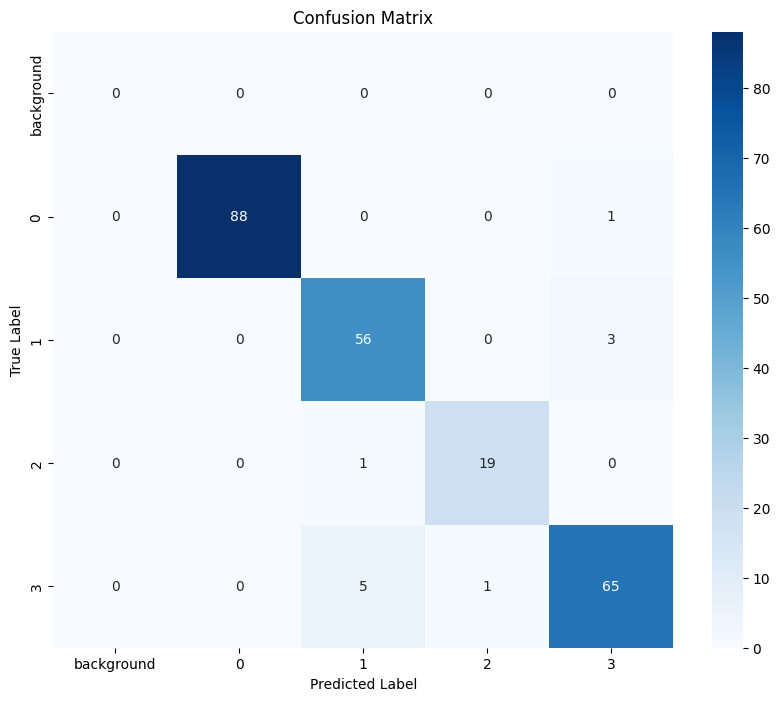


Classification Report:

              precision    recall  f1-score   support

  background       0.00      0.00      0.00         0
           0       1.00      0.92      0.96        96
           1       0.90      0.89      0.90        63
           2       0.95      0.86      0.90        22
           3       0.94      0.77      0.85        84

    accuracy                           0.86       265
   macro avg       0.76      0.69      0.72       265
weighted avg       0.95      0.86      0.90       265



Recall and F-score are ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
Recall and F-score are ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
Recall and F-score are ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.


In [4]:
import torch
import torchvision
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torch.utils.data import DataLoader
import torchvision.transforms as T
import json
import os
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt
from PIL import Image

# Custom Dataset Class
class CustomDataset(torch.utils.data.Dataset):
    def __init__(self, image_dir, annotation_file, transforms=None):
        self.image_dir = image_dir
        self.transforms = transforms

        # Load COCO annotations
        with open(annotation_file, 'r') as f:
            self.coco = json.load(f)

        # Extract image IDs and categories
        self.image_ids = [img['id'] for img in self.coco['images']]
        self.img_id_to_path = {img['id']: img['file_name'] for img in self.coco['images']}
        self.categories = {cat['id']: cat['name'] for cat in self.coco['categories']}
        self.category_to_idx = {cat: idx for idx, cat in enumerate(self.categories.values())}

        # Load annotations
        self.img_id_to_annotations = self._load_annotations()

    def _load_annotations(self):
        img_id_to_annotations = {}
        for ann in self.coco['annotations']:
            img_id = ann['image_id']
            bbox = ann['bbox']
            category_id = ann['category_id']
            if img_id not in img_id_to_annotations:
                img_id_to_annotations[img_id] = {'boxes': [], 'labels': []}
            img_id_to_annotations[img_id]['boxes'].append([bbox[0], bbox[1], bbox[0] + bbox[2], bbox[1] + bbox[3]])
            img_id_to_annotations[img_id]['labels'].append(self.category_to_idx[self.categories[category_id]])
        return img_id_to_annotations

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, idx):
        img_id = self.image_ids[idx]
        image_path = os.path.join(self.image_dir, self.img_id_to_path[img_id])
        image = Image.open(image_path).convert("RGB")

        targets = self.img_id_to_annotations.get(img_id, {'boxes': [], 'labels': []})
        boxes = torch.tensor(targets['boxes'], dtype=torch.float32)
        labels = torch.tensor(targets['labels'], dtype=torch.int64)
        targets = {'boxes': boxes, 'labels': labels}

        if self.transforms:
            image = self.transforms(image)

        return image, targets

def collate_fn(batch):
    return tuple(zip(*batch))

def load_model(model_path, num_classes):
    model = fasterrcnn_resnet50_fpn(pretrained=False)
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = torchvision.models.detection.faster_rcnn.FastRCNNPredictor(in_features, num_classes)
    model.load_state_dict(torch.load(model_path))
    model.eval()
    return model

def evaluate_model_single_class(model, dataloader, device):
    model.eval()
    all_labels = []
    all_preds = []

    with torch.no_grad():
        for images, targets in dataloader:
            images = [img.to(device) for img in images]
            outputs = model(images)

            for i, output in enumerate(outputs):
                if output['labels'].shape[0] > 0:
                    # Get the highest confidence prediction
                    max_conf_idx = torch.argmax(output['scores']).item()
                    pred_label = output['labels'][max_conf_idx].cpu().item()
                else:
                    pred_label = -1  # No detection

                if targets[i]['labels'].numel() > 0:
                    true_label = targets[i]['labels'][0].cpu().item()  # Assuming one true label per image
                else:
                    true_label = -1  # No ground truth label

                all_preds.append(pred_label)
                all_labels.append(true_label)

    return np.array(all_labels), np.array(all_preds)

def plot_confusion_matrix(true_labels, pred_labels, class_names):
    conf_matrix = confusion_matrix(true_labels, pred_labels, labels=np.arange(len(class_names)))

    plt.figure(figsize=(10, 8))
    sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.title('Confusion Matrix')
    plt.show()

    print("\nClassification Report:\n")
    print(classification_report(true_labels, pred_labels, target_names=class_names))

# Define transformations
transforms = T.Compose([
    T.ToTensor(),
    T.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),
])

# Paths to your test dataset
test_image_dir = '/content/FinallySAVE-1/test'
test_annotation_file = '/content/FinallySAVE-1/test/_annotations.coco.json'

# Load test dataset
test_dataset = CustomDataset(test_image_dir, test_annotation_file, transforms)
test_loader = DataLoader(test_dataset, batch_size=4, shuffle=False, num_workers=2, collate_fn=collate_fn)

# Load the pre-trained model
model_path = '/content/faster_rcnn_model.pth'
categories = ['background','0', '1', '2', '3']  # Include all actual classes
num_classes = len(categories)
model = load_model(model_path, num_classes)

# Move model to GPU if available
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model.to(device)

# Evaluate the model
true_labels, pred_labels = evaluate_model_single_class(model, test_loader, device)

# Plot confusion matrix
if len(true_labels) > 0 and len(pred_labels) > 0:
    plot_confusion_matrix(true_labels, pred_labels, categories)
else:
    print("No valid data available for confusion matrix computation.")


## CONF MATR

The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` fo

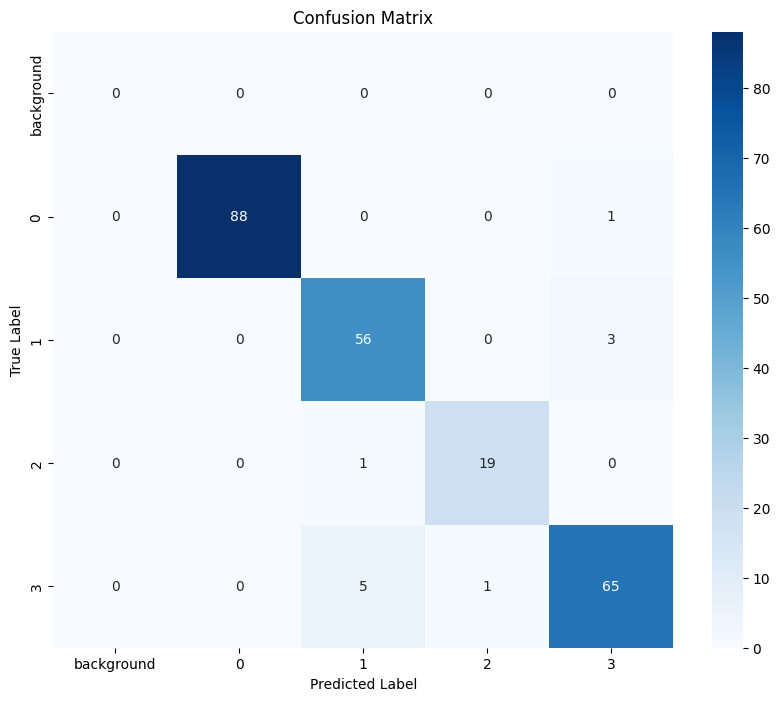


Classification Report:

              precision    recall  f1-score   support

  background       0.00      0.00      0.00         0
           0       1.00      0.92      0.96        96
           1       0.90      0.89      0.90        63
           2       0.95      0.86      0.90        22
           3       0.94      0.77      0.85        84

    accuracy                           0.86       265
   macro avg       0.76      0.69      0.72       265
weighted avg       0.95      0.86      0.90       265



Recall and F-score are ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
Recall and F-score are ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
Recall and F-score are ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.


In [5]:
import torch
import torchvision
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torch.utils.data import DataLoader
import torchvision.transforms as T
import json
import os
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt
from PIL import Image

class CustomDataset(torch.utils.data.Dataset):
    def __init__(self, image_dir, annotation_file, transforms=None):
        self.image_dir = image_dir
        self.transforms = transforms

        # Load COCO annotations
        with open(annotation_file, 'r') as f:
            self.coco = json.load(f)

        # Create mappings
        self.image_ids = [img['id'] for img in self.coco['images']]
        self.img_id_to_path = {img['id']: img['file_name'] for img in self.coco['images']}
        self.categories = {cat['id']: cat['name'] for cat in self.coco['categories']}
        self.category_to_idx = {cat: idx for idx, cat in enumerate(self.categories.values())}

        # Create UUID to numerical ID mapping
        self.img_path_to_id = {img['file_name']: img['id'] for img in self.coco['images']}
        self.img_id_to_annotations = self._load_annotations()

    def _load_annotations(self):
        img_id_to_annotations = {}
        for ann in self.coco['annotations']:
            img_id = ann['image_id']
            bbox = ann['bbox']
            category_id = ann['category_id']
            if img_id not in img_id_to_annotations:
                img_id_to_annotations[img_id] = {'boxes': [], 'labels': []}
            img_id_to_annotations[img_id]['boxes'].append([bbox[0], bbox[1], bbox[0] + bbox[2], bbox[1] + bbox[3]])
            img_id_to_annotations[img_id]['labels'].append(self.category_to_idx[self.categories[category_id]])
        return img_id_to_annotations

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, idx):
        img_id = self.image_ids[idx]
        image_path = os.path.join(self.image_dir, self.img_id_to_path[img_id])
        image = Image.open(image_path).convert("RGB")

        targets = self.img_id_to_annotations.get(img_id, {'boxes': [], 'labels': []})
        boxes = torch.tensor(targets['boxes'], dtype=torch.float32)
        labels = torch.tensor(targets['labels'], dtype=torch.int64)
        targets = {'boxes': boxes, 'labels': labels}

        if self.transforms:
            image = self.transforms(image)

        return image, targets, img_id  # Return img_id for reference


def collate_fn(batch):
    return tuple(zip(*batch))

# Create DataLoader
test_loader = DataLoader(test_dataset, batch_size=4, shuffle=False, num_workers=2, collate_fn=collate_fn)

def load_model(model_path, num_classes):
    model = fasterrcnn_resnet50_fpn(pretrained=False)
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = torchvision.models.detection.faster_rcnn.FastRCNNPredictor(in_features, num_classes)
    model.load_state_dict(torch.load(model_path))
    model.eval()
    return model

def evaluate_model_single_class(model, dataloader, device):
    model.eval()
    all_labels = []
    all_preds = []

    with torch.no_grad():
        for images, targets, img_ids in dataloader:  # Handle three values
            images = [img.to(device) for img in images]
            outputs = model(images)

            for i, output in enumerate(outputs):
                if output['labels'].shape[0] > 0:
                    # Get the highest confidence prediction
                    max_conf_idx = torch.argmax(output['scores']).item()
                    pred_label = output['labels'][max_conf_idx].cpu().item()
                else:
                    pred_label = -1  # No detection

                if targets[i]['labels'].numel() > 0:
                    true_label = targets[i]['labels'][0].cpu().item()  # Assuming one true label per image
                else:
                    true_label = -1  # No ground truth label

                all_preds.append(pred_label)
                all_labels.append(true_label)

    return np.array(all_labels), np.array(all_preds)


def plot_confusion_matrix(true_labels, pred_labels, class_names):
    conf_matrix = confusion_matrix(true_labels, pred_labels, labels=np.arange(len(class_names)))

    plt.figure(figsize=(10, 8))
    sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.title('Confusion Matrix')
    plt.show()

    print("\nClassification Report:\n")
    print(classification_report(true_labels, pred_labels, target_names=class_names))

# Define transformations
transforms = T.Compose([
    T.ToTensor(),
    T.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),
])

# Paths to your test dataset
test_image_dir = '/content/FinallySAVE-1/test'
test_annotation_file = '/content/FinallySAVE-1/test/_annotations.coco.json'

# Load test dataset
test_dataset = CustomDataset(test_image_dir, test_annotation_file, transforms)
test_loader = DataLoader(test_dataset, batch_size=4, shuffle=False, num_workers=2, collate_fn=collate_fn)

# Load the pre-trained model
model_path = '/content/faster_rcnn_model.pth'
categories = ['background','0', '1', '2', '3']  # Include all actual classes
num_classes = len(categories)
model = load_model(model_path, num_classes)

# Move model to GPU if available
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model.to(device)

# Evaluate the model
true_labels, pred_labels = evaluate_model_single_class(model, test_loader, device)

# Plot confusion matrix
if len(true_labels) > 0 and len(pred_labels) > 0:
    plot_confusion_matrix(true_labels, pred_labels, categories)
else:
    print("No valid data available for confusion matrix computation.")


## Confusion matrix

In [7]:
def print_confusion_matrix(true_labels, pred_labels, class_names):
    conf_matrix = confusion_matrix(true_labels, pred_labels, labels=np.arange(len(class_names)))

    print("\nConfusion Matrix:")
    print(conf_matrix)

    print("\nClassification Report:")
    print(classification_report(true_labels, pred_labels, target_names=class_names))

# Example usage
true_labels, pred_labels = evaluate_model_single_class(model, test_loader, device)

# Print confusion matrix and classification report
if len(true_labels) > 0 and len(pred_labels) > 0:
    print_confusion_matrix(true_labels, pred_labels, categories)
else:
    print("No valid data available for confusion matrix computation.")



Confusion Matrix:
[[ 0  0  0  0  0]
 [ 0 88  0  0  1]
 [ 0  0 56  0  3]
 [ 0  0  1 19  0]
 [ 0  0  5  1 65]]

Classification Report:
              precision    recall  f1-score   support

  background       0.00      0.00      0.00         0
           0       1.00      0.92      0.96        96
           1       0.90      0.89      0.90        63
           2       0.95      0.86      0.90        22
           3       0.94      0.77      0.85        84

    accuracy                           0.86       265
   macro avg       0.76      0.69      0.72       265
weighted avg       0.95      0.86      0.90       265



Recall and F-score are ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
Recall and F-score are ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
Recall and F-score are ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.


## COnfusion matrix normalized


invalid value encountered in divide


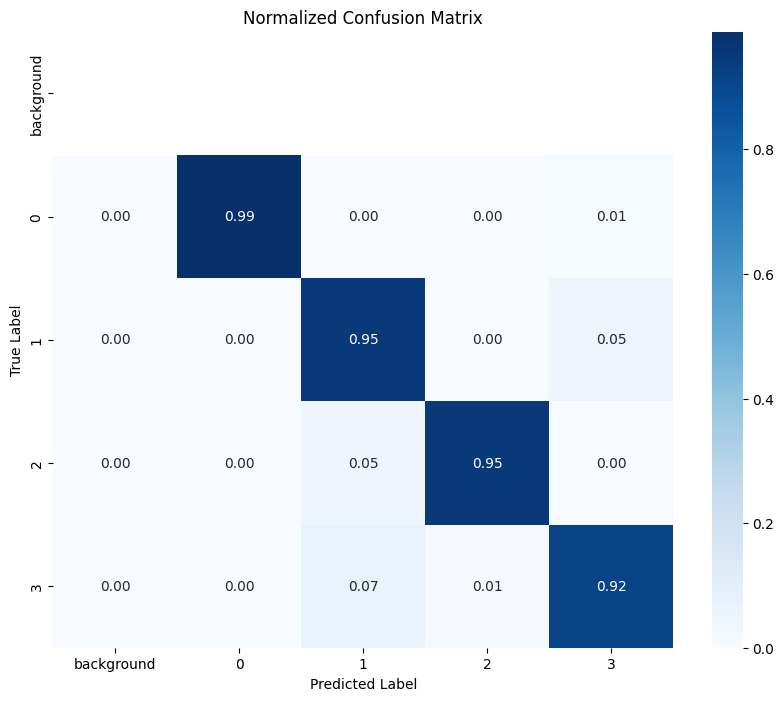


Classification Report:

              precision    recall  f1-score   support

  background       0.00      0.00      0.00         0
           0       1.00      0.92      0.96        96
           1       0.90      0.89      0.90        63
           2       0.95      0.86      0.90        22
           3       0.94      0.77      0.85        84

    accuracy                           0.86       265
   macro avg       0.76      0.69      0.72       265
weighted avg       0.95      0.86      0.90       265



Recall and F-score are ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
Recall and F-score are ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
Recall and F-score are ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.


In [8]:
def plot_normalized_confusion_matrix(true_labels, pred_labels, class_names):
    conf_matrix = confusion_matrix(true_labels, pred_labels, labels=np.arange(len(class_names)))

    # Normalize the confusion matrix
    conf_matrix_normalized = conf_matrix.astype('float') / conf_matrix.sum(axis=1)[:, np.newaxis]

    plt.figure(figsize=(10, 8))
    sns.heatmap(conf_matrix_normalized, annot=True, fmt=".2f", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.title('Normalized Confusion Matrix')
    plt.show()

    print("\nClassification Report:\n")
    print(classification_report(true_labels, pred_labels, target_names=class_names))

# Plot the normalized confusion matrix
if len(true_labels) > 0 and len(pred_labels) > 0:
    plot_normalized_confusion_matrix(true_labels, pred_labels, categories)
else:
    print("No valid data available for confusion matrix computation.")


## Testing



In [9]:
# Path to COCO annotation file
annotation_file = '/content/FinallySAVE-1/test/_annotations.coco.json'

# Create an ID map
coco_gt = COCO(annotation_file)
id_map = {img['file_name']: img['id'] for img in coco_gt.loadImgs(coco_gt.getImgIds())}


NameError: name 'COCO' is not defined

You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.


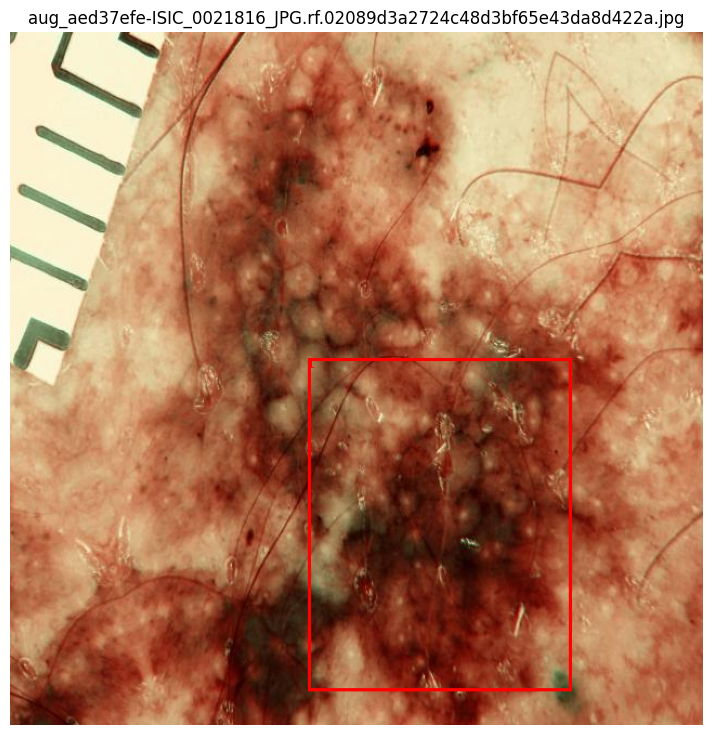

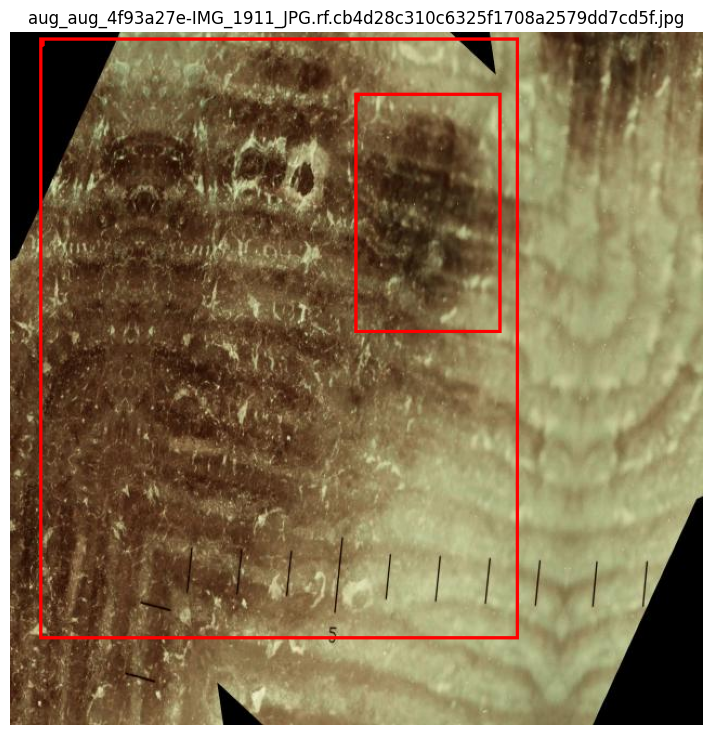

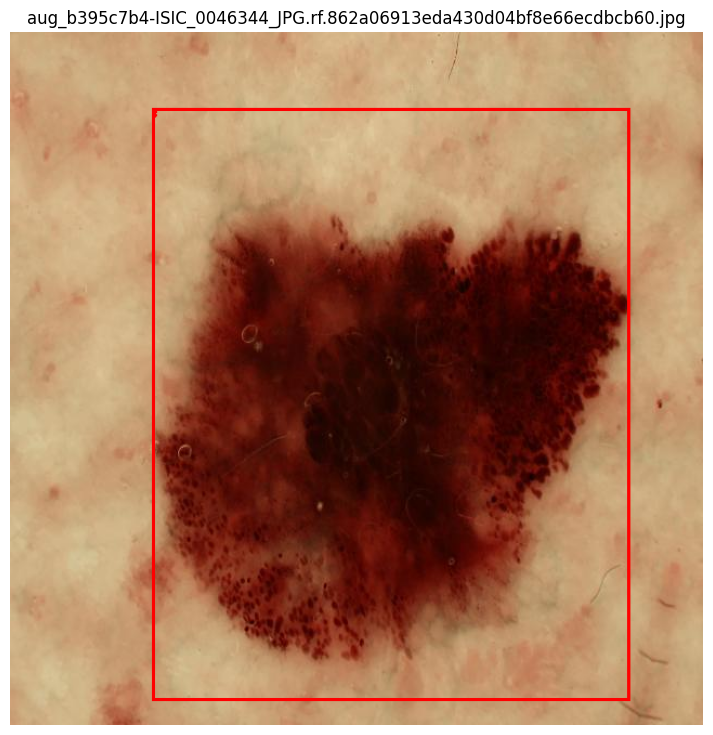

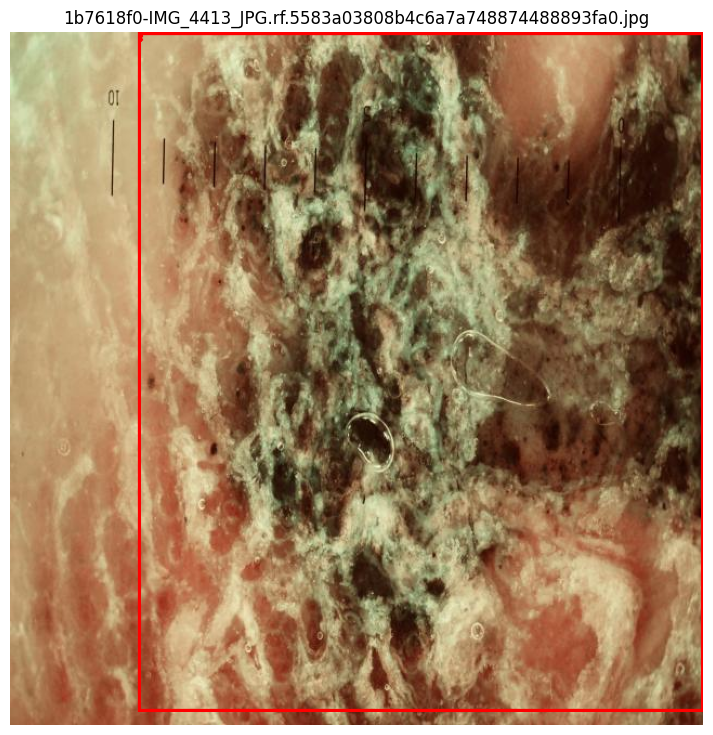

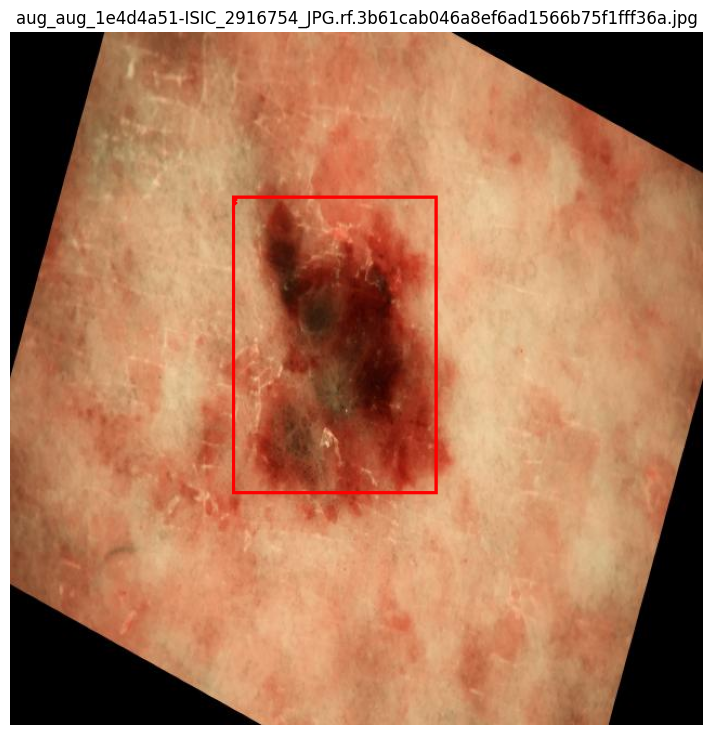

...

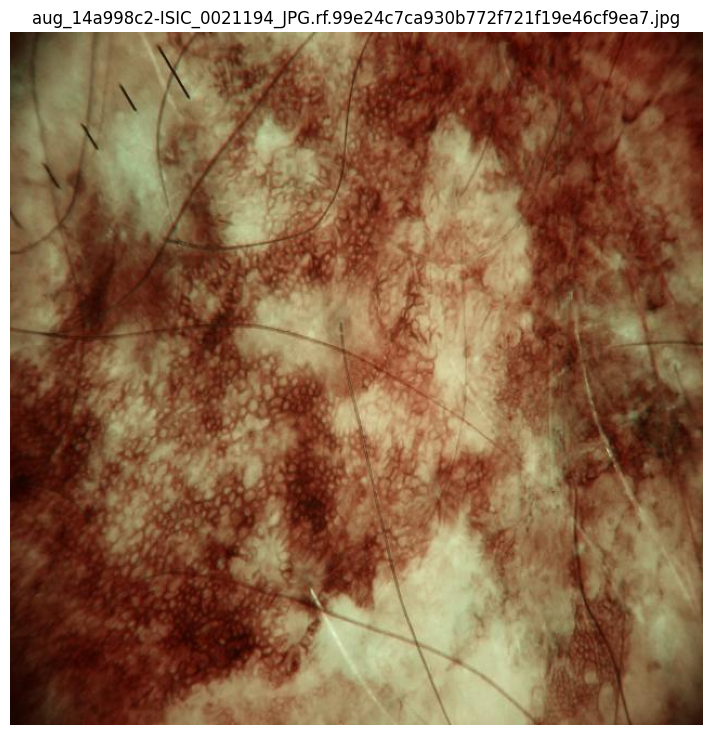

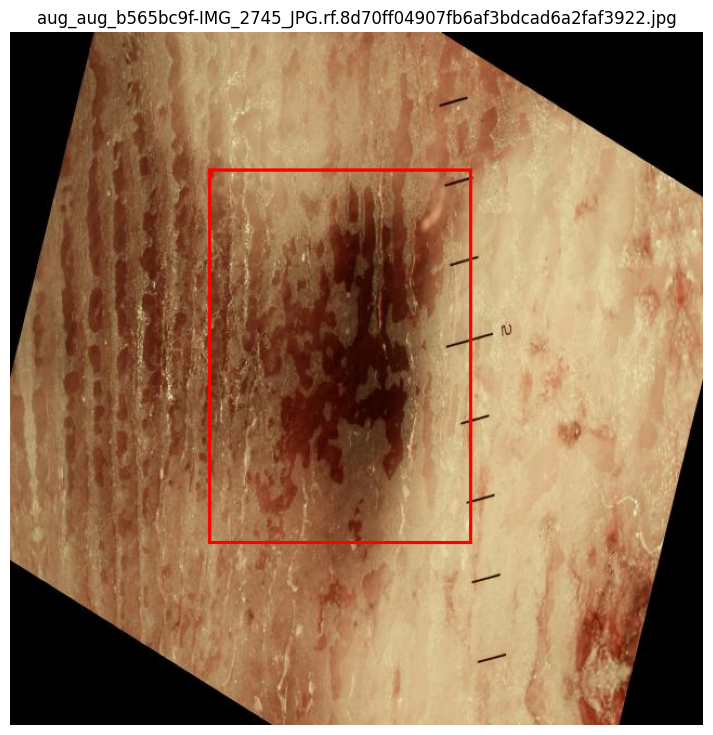

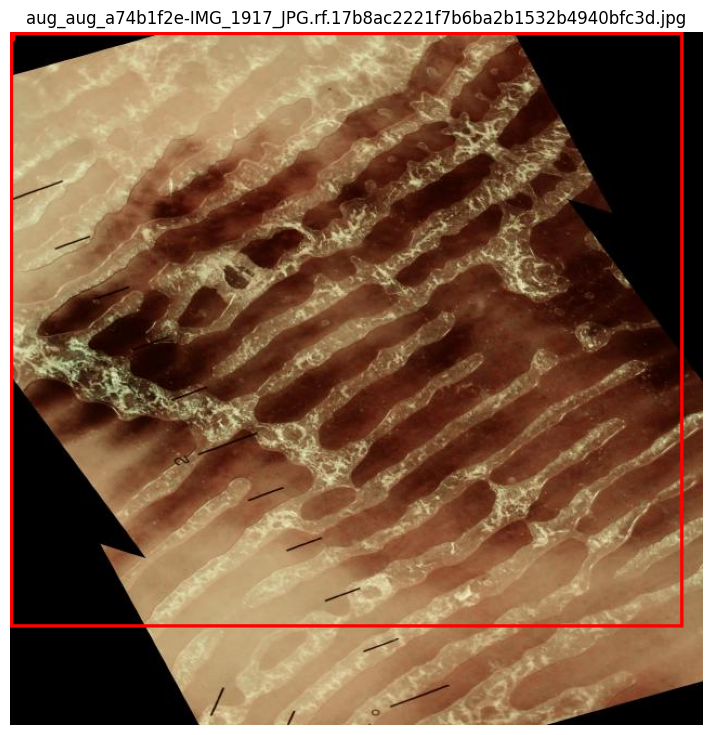

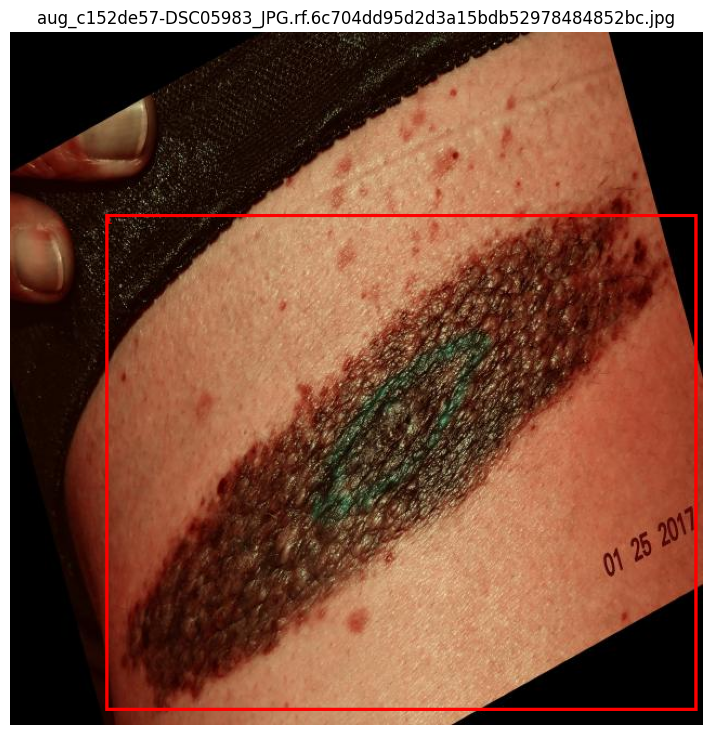

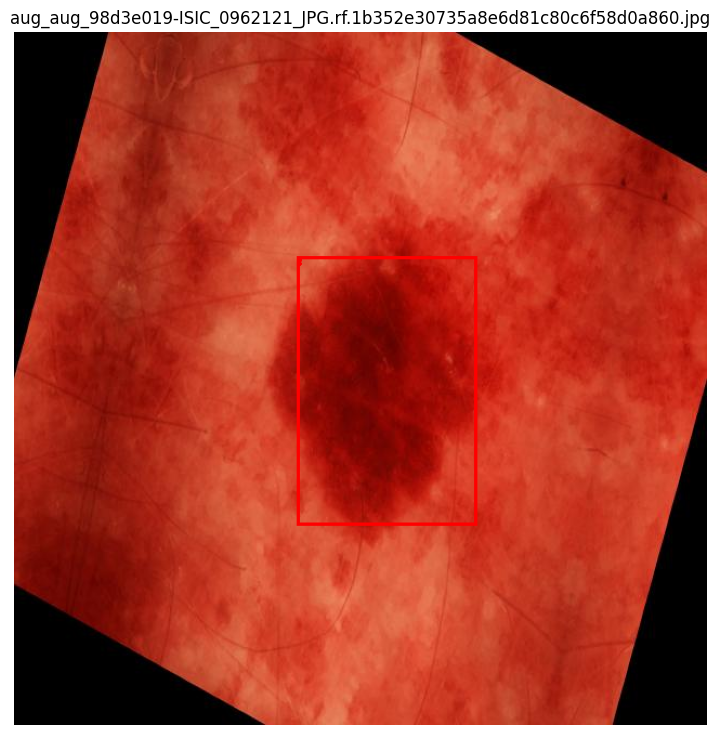

In [ ]:
import torch
import torchvision
from torchvision.models.detection import fasterrcnn_resnet50_fpn
import torchvision.transforms as T
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import numpy as np
import os

# Load the pre-trained model
def load_model(model_path, num_classes):
    model = fasterrcnn_resnet50_fpn(pretrained=False)
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = torchvision.models.detection.faster_rcnn.FastRCNNPredictor(in_features, num_classes)
    model.load_state_dict(torch.load(model_path))
    model.eval()
    return model

# Define the transformations
def get_transforms():
    return T.Compose([
        T.ToTensor(),
        T.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),
    ])

# Function to visualize detections
def visualize_predictions(image, predictions, category_names):
    image = image.convert("RGB")
    draw = ImageDraw.Draw(image)
    for score, label, bbox in zip(predictions['scores'], predictions['labels'], predictions['boxes']):
        if score > 0.5:  # Threshold for displaying bounding boxes
            bbox = [int(x) for x in bbox]
            draw.rectangle(bbox, outline="red", width=3)
            draw.text((bbox[0], bbox[1]), f"{category_names[label]}", fill="red")
    return image

# Load the model
model_path = '/content/faster_rcnn_model.pth'
categories = ['background','0','1', '2', '3']  # Include all actual classes
num_classes = len(categories)
model = load_model(model_path, num_classes)

# Move model to GPU if available
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model.to(device)

# Define the transformations
transform = get_transforms()

# Path to your images directory
image_dir = '/content/FinallySAVE-1/test'

# Process each image in the directory
for image_name in os.listdir(image_dir):
    image_path = os.path.join(image_dir, image_name)

    if image_path.lower().endswith(('.png', '.jpg', '.jpeg')):
        image = Image.open(image_path).convert("RGB")
        image_tensor = transform(image).unsqueeze(0).to(device)

        with torch.no_grad():
            outputs = model(image_tensor)

        predictions = outputs[0]  # Get predictions for the first image in the batch
        image_with_boxes = visualize_predictions(image, predictions, categories)

        # Display the image with bounding boxes
        plt.figure(figsize=(12, 9))
        plt.imshow(image_with_boxes)
        plt.title(image_name)
        plt.axis('off')
        plt.show()


In [ ]:

from google.colab import drive
drive.mount('/content/drive')


In [ ]:

torch.save(model.state_dict(), '/content/drive/MyDrive/faster_rcnn_model.pth')


In [ ]:


from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
import json

# ... (rest of your code) ...

def save_predictions_as_json(predictions, image_ids, categories, output_file):
    """
    Saves object detection predictions in COCO format to a JSON file.

    Args:
        predictions: A list of dictionaries containing prediction information.
        image_ids: A list of image IDs corresponding to the predictions.
        categories: A list of category names.
        output_file: The path to the output JSON file.
    """
    predictions_coco_format = []
    for i, prediction in enumerate(predictions):
        for j in range(len(prediction['boxes'])):
            bbox = prediction['boxes'][j].cpu().numpy().tolist()
            score = prediction['scores'][j].cpu().item()
            label = prediction['labels'][j].cpu().item()

            # Convert bounding box format from [xmin, ymin, xmax, ymax] to [xmin, ymin, width, height]
            bbox[2] = bbox[2] - bbox[0]
            bbox[3] = bbox[3] - bbox[1]

            predictions_coco_format.append({
                'image_id': image_ids[i],
                'category_id': label,
                'bbox': bbox,
                'score': score
            })

    with open(output_file, 'w') as f:
        json.dump(predictions_coco_format, f)

# ... (rest of your code) ...

# Save predictions to a JSON file
output_file = '/content/predictions.json'
save_predictions_as_json(predictions, image_ids, categories, output_file)


In [ ]:

from google.colab import files
files.download('/content/predictions.json')


In [ ]:
!zip -r /content/drive/MyDrive/fasterRCNN.zip /content/drive/MyDrive/fasterRCNN
from google.colab import files
files.download("/content/predictions.json")

In [ ]:
def compute_map(predictions, groundtruths, annotation_file):
    # Load COCO ground truth object
    coco_gt = COCO(annotation_file)

    # Convert predictions to COCO format
    coco_dt = coco_gt.loadRes(predictions)

    # Initialize COCOeval object
    coco_eval = COCOeval(coco_gt, coco_dt, 'bbox')
    coco_eval.evaluate()
    coco_eval.accumulate()
    coco_eval.summarize()

    return coco_eval.stats[0]  # mAP across all IoU thresholds

# Compute mAP
map_score = compute_map(predictions, groundtruths, test_annotation_file)
print(f'mAP: {map_score:.4f}')
